In [3]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files


In [12]:
def hist(img, title="Histograma"):
    plt.figure(figsize=(5, 4))
    plt.hist(img.ravel(), bins=256, range=(0, 255), color="gray")
    plt.title(title)
    plt.xlabel("Intensidade")
    plt.ylabel("Nº de pixels")
    plt.tight_layout()
    plt.show()

def plot_comparison(bef, aft, title_bef, title_aft, img_name):
    fig, ax = plt.subplots(2, 2, figsize=(10, 8))

    ax[0, 0].imshow(bef, cmap="gray", vmin=0, vmax=255)
    ax[0, 0].set_title(title_bef)
    ax[0, 0].axis("off")

    ax[0, 1].imshow(aft, cmap="gray", vmin=0, vmax=255)
    ax[0, 1].set_title(title_aft)
    ax[0, 1].axis("off")

    ax[1, 0].hist(bef.ravel(), bins=256, range=(0, 255), color="gray")
    ax[1, 0].set_title(f"Histograma — {title_bef}")
    ax[1, 0].set_xlabel("Intensidade")
    ax[1, 0].set_ylabel("Nº de pixels")

    ax[1, 1].hist(aft.ravel(), bins=256, range=(0, 255), color="gray")
    ax[1, 1].set_title(f"Histograma — {title_aft}")
    ax[1, 1].set_xlabel("Intensidade")
    ax[1, 1].set_ylabel("Nº de pixels")

    plt.tight_layout()
    plt.savefig(img_name, dpi=200, bbox_inches="tight")
    plt.show()


def stats(img):
    media = img.mean()
    desvio = img.std()
    pct_escuros = (img < 50).mean() * 100
    pct_claros = (img > 200).mean() * 100
    print(f"Média de intensidade: {media:.1f}")
    print(f"Desvio-padrão:        {desvio:.1f}")
    print(f"% de pixels < 50  (região escura): {pct_escuros:.1f}%")
    print(f"% de pixels > 200 (região clara):  {pct_claros:.1f}%")
    return media, desvio, pct_escuros, pct_claros


def plus_contrast(img, L=None, H=None):
    if L is None:
        L = int(img.min())
    if H is None:
        H = int(img.max())
    img_f = img.astype(np.float32)
    saida = (img_f - L) * (255.0 / (H - L))
    return np.clip(saida, 0, 255).astype(np.uint8)


def equalize(img):
    return cv2.equalizeHist(img)


def gamma_correction(img, gamma):
    inv_gamma = 1.0 / gamma
    tabela = np.array(
        [((i / 255.0) ** inv_gamma) * 255 for i in range(256)]
    ).astype(np.uint8)
    return cv2.LUT(img, tabela)



## Imagem Escura


Saving escuro.jpg to escuro (1).jpg


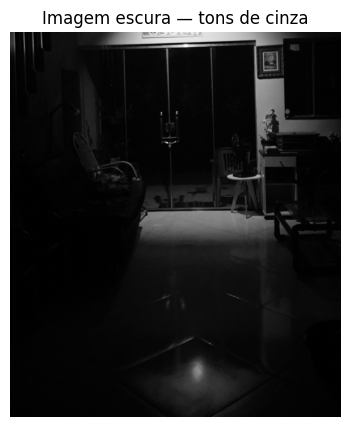

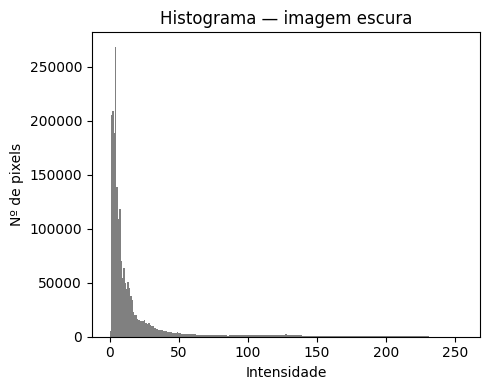

Média de intensidade: 17.9
Desvio-padrão:        32.9
% de pixels < 50  (região escura): 91.4%
% de pixels > 200 (região clara):  0.7%


(np.float64(17.865296795338676),
 np.float64(32.85067523264005),
 np.float64(91.42120356882738),
 np.float64(0.6571831755280408))

In [13]:
img_dark = files.upload()
name_dark = next(iter(img_dark))
img_dark_bgr = cv2.imread(name_dark)
img_dark_gray = cv2.cvtColor(img_dark_bgr, cv2.COLOR_BGR2GRAY)

plt.figure(figsize=(5, 5))
plt.imshow(img_dark_gray, cmap="gray", vmin=0, vmax=255)
plt.title("Imagem escura — tons de cinza")
plt.axis("off")
plt.show()

hist(img_dark_gray, "Histograma — imagem escura")
stats(img_dark_gray)


As intensidades estão concentradas na região escura, com 91,4% dos pixels abaixo do nível 50 e uma média baixa (17.9). Isso revela um histograma espremido na extremidade esquerda, indicando subexposição e perda de detalhes nas sombras profundas.

Irei utilizar gamma 2.5, a correção gama não linear (com γ > 1) vai mapear a massa de pixels muito escuros em direção aos tons médios, revelando os detalhes escondidos na escuridão. Ao mesmo tempo, ela comprime as altas frequências, evitando que os raros pixels já claros (0,7%) sejam estourados para o branco puro.

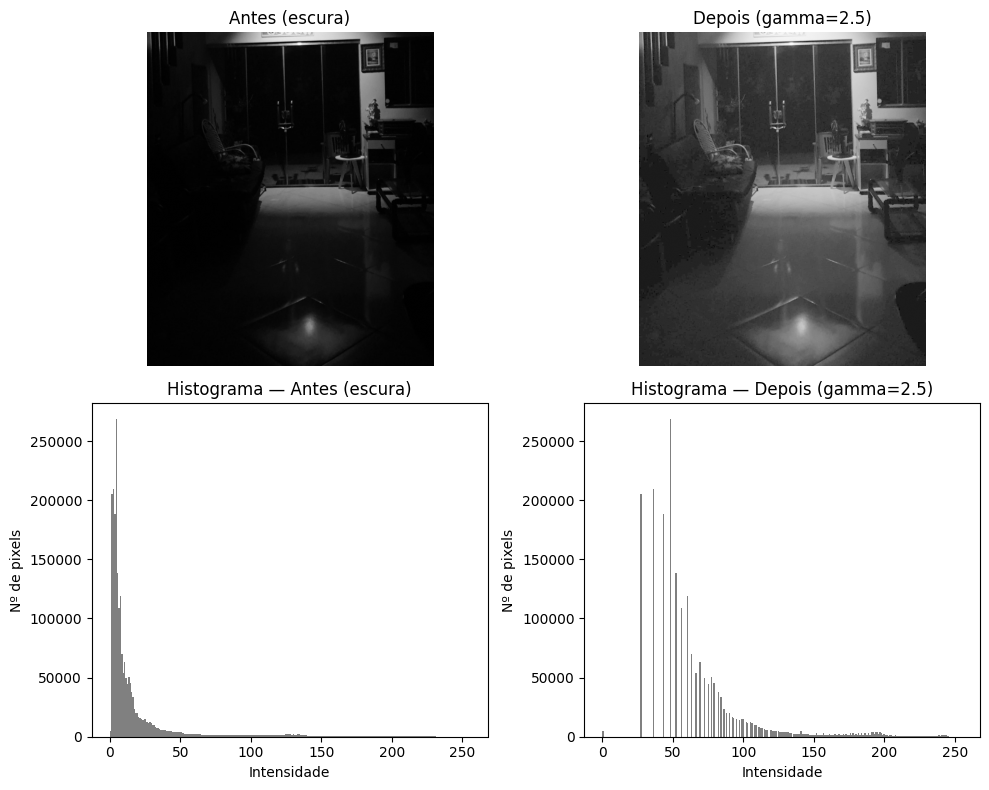

In [20]:
gamma_dark = 2.5
img_dark_corr = gamma_correction(img_dark_gray, gamma_dark)

plot_comparison(
    img_dark_gray, img_dark_corr,
    "Antes (escura)", f"Depois (gamma={gamma_dark})",
    "comparacao_escura.png",
)



## Imagem Clara


Saving claro.jpg to claro (2).jpg


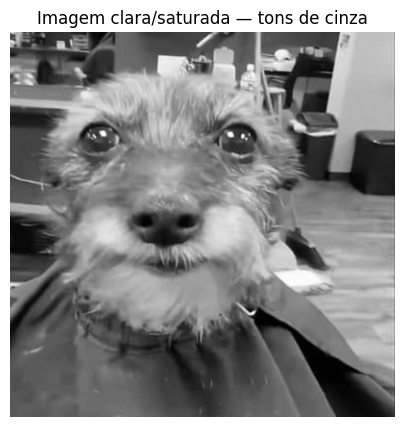

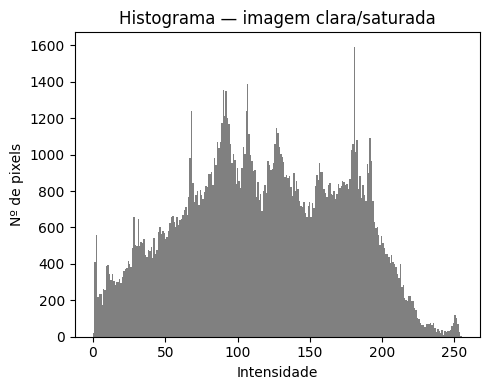

Média de intensidade: 117.9
Desvio-padrão:        55.7
% de pixels < 50  (região escura): 12.9%
% de pixels > 200 (região clara):  5.9%


(np.float64(117.86190625),
 np.float64(55.69887217319764),
 np.float64(12.8725),
 np.float64(5.936875))

In [21]:
img_bright = files.upload()
name_bright = next(iter(img_bright))
img_bright_bgr = cv2.imread(name_bright)
img_bright_gray = cv2.cvtColor(img_bright_bgr, cv2.COLOR_BGR2GRAY)

plt.figure(figsize=(5, 5))
plt.imshow(img_bright_gray, cmap="gray", vmin=0, vmax=255)
plt.title("Imagem clara/saturada — tons de cinza")
plt.axis("off")
plt.show()

hist(img_bright_gray, "Histograma — imagem clara/saturada")
stats(img_bright_gray)


A imagem possui uma concentração significativa de luz, com quase 6% da imagem acima da marca de 200 (região clara) e poucos pretos profundos (apenas 12,9% < 50). Isso gera um aspecto sem densidade, onde o excesso de luz comprime os detalhes.

irei escolher o gamma 0.4, com esse histograma tão deslocado pra direita, γ = 0,4 deve escurece bastante sem perder detalhes

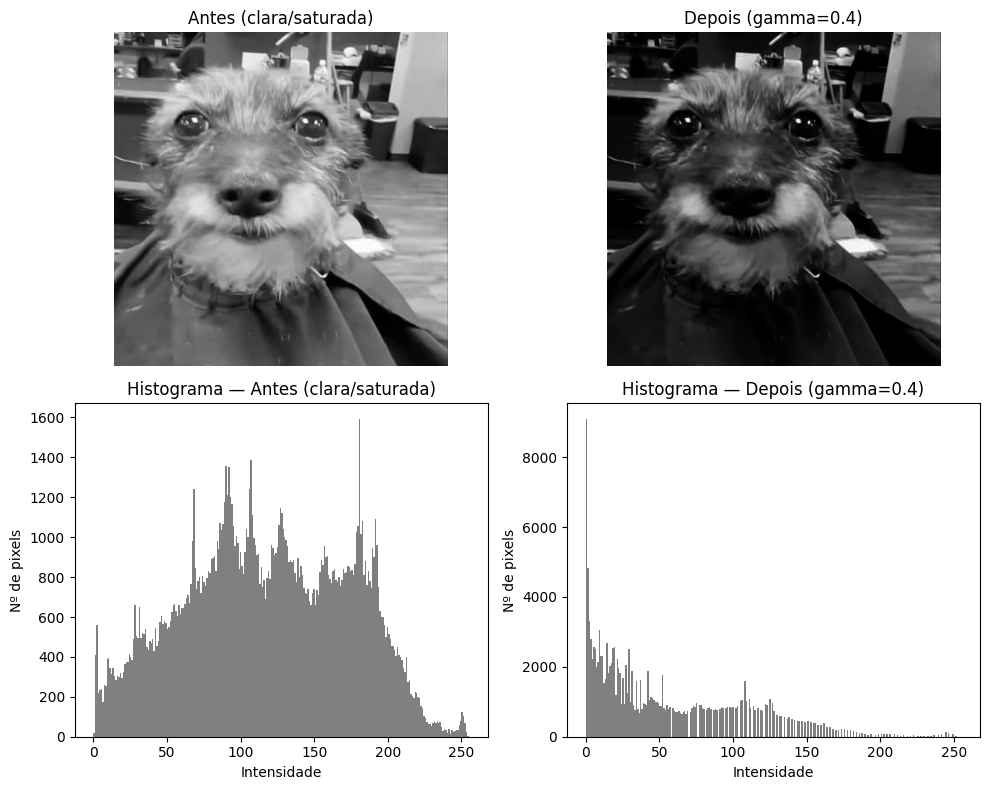

In [22]:
gamma_bright = 0.4
img_bright_corr = gamma_correction(img_bright_gray, gamma_bright)

plot_comparison(
    img_bright_gray, img_bright_corr,
    "Antes (clara/saturada)", f"Depois (gamma={gamma_bright})",
    "comparacao_clara.png",
)



## Imagem bem exposta


Saving catarina.jpg to catarina (1).jpg


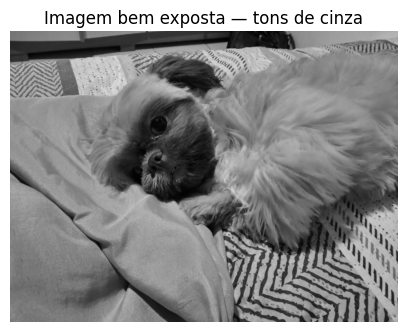

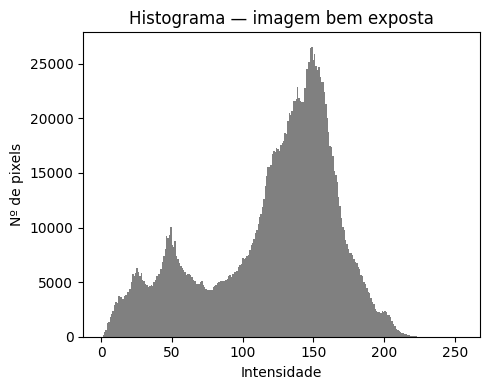

Média de intensidade: 120.7
Desvio-padrão:        46.4
% de pixels < 50  (região escura): 12.1%
% de pixels > 200 (região clara):  0.9%


(np.float64(120.74748802083333),
 np.float64(46.426623745302415),
 np.float64(12.051614583333334),
 np.float64(0.9459375000000001))

In [18]:
img_normal = files.upload()
name_normal = next(iter(img_normal))
img_normal_bgr = cv2.imread(name_normal)
img_normal_gray = cv2.cvtColor(img_normal_bgr, cv2.COLOR_BGR2GRAY)

plt.figure(figsize=(5, 5))
plt.imshow(img_normal_gray, cmap="gray", vmin=0, vmax=255)
plt.title("Imagem bem exposta — tons de cinza")
plt.axis("off")
plt.show()

hist(img_normal_gray, "Histograma — imagem bem exposta")
stats(img_normal_gray)


O histograma demonstra um otimo equilíbrio, com a média centralizada (120.7) e um desvio-padrão saudável (46.4). Há uma distribuição rica de tons médios e as extremidades não apresentam picos aglomerados, caracterizando uma imagem com boa preservação de detalhes em todo o espectro.

Sendo uma imagem já equilibrada, a expansão de contraste linear é a escolha, ela pegará os valores atuais e os esticará até encostar nos limites 0 e 255. Isso remove qualquer leve sensação de imagem "cinzenta" sem distorcer o ótimo equilíbrio original.

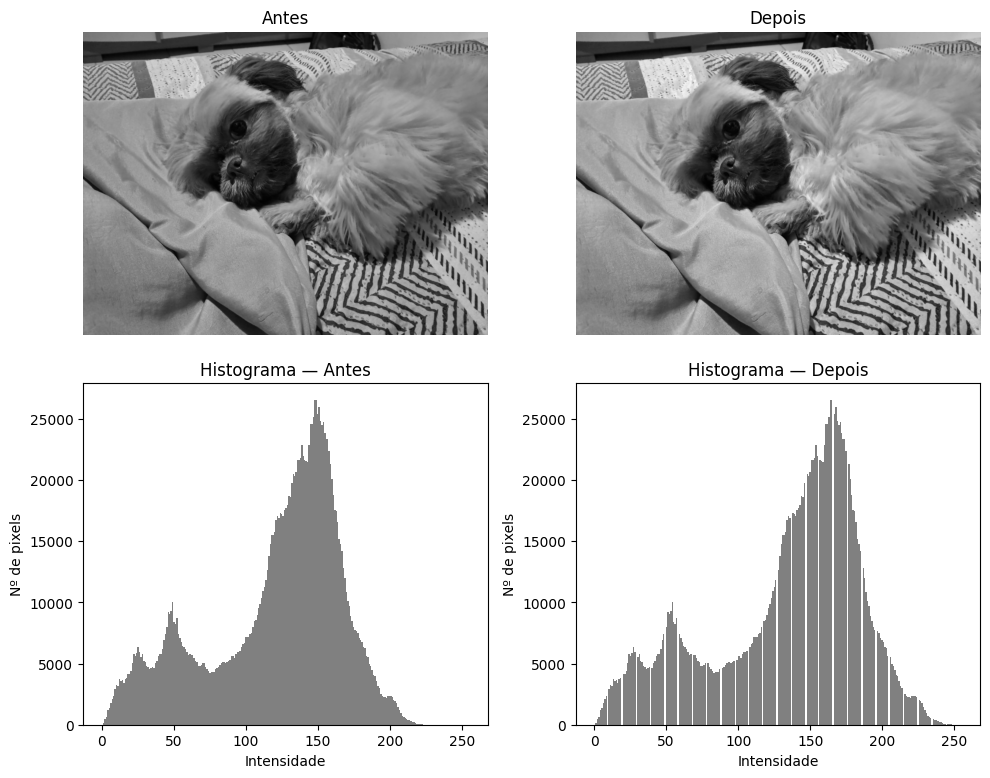

In [24]:
img_normal_equalized = plus_contrast(img_normal_gray)

plot_comparison(
    img_normal_gray, img_normal_equalized,
    "Antes", "Depois",
    "comparacao_boa.png",
)


A operação fez menos diferença na Imagem 3 (bem exposta). Como ela original já apresentava um desvio-padrão de 46.4 e uma média perto de 127, os pixels já se espalhavam pela maior parte do histograma natural. A aplicação da expansão de contraste apenas ajustou os limites, sendo uma mudança sutil no brilho. Porém, as Imagens 1 e 2 possuíam falhas de iluminação e exigiam remapeamentos de áreas ociosas para voltarem a ter informação visível.